# A2 · Archive: superseded figures

**Status.** Archive. These are versions of Fig. 5 and Fig. 6 that the paper no longer uses, kept so that they stay reproducible. The paper's own Fig. 5 and Fig. 6 are drawn in notebook 06.

**Purpose.** Reproduce:

- Fig. 5 with three panels (M2, M3 and M4), on the daytime low and on the whole-day minimum. The paper's Fig. 5 has four panels (it adds M5) and shows the daytime low only.
- Fig. 6 on the whole-day minimum. The paper's Fig. 6 shows the daytime low.

**Inputs**

- `data/interim/forecasts.parquet` from notebook 05.

**Outputs** (`outputs/archive`)

- `fig5_daytime_low` and `fig5_minimum` (each as PNG at 600 dpi and PDF).
- `fig6_minimum` (PNG and PDF) and `fig6_minimum_data.csv`.

**Main process**

1. Set up.
2. Fig. 5 with three panels, for both targets.
3. Fig. 6 on the whole-day minimum.
4. Result.

Run notebook 05 first.

## 1. Set up

In [1]:
import pandas as pd

from pynmdf import evaluate, plots
from pynmdf.config import load_config

cfg = load_config()
interim, archive = cfg["dirs"]["interim"], cfg["dirs"]["archive"]
plots.set_style()

pd.set_option("display.width", 220, "display.max_columns", 30)
pd.set_option("display.float_format", "{:,.0f}".format)
forecasts = pd.read_parquet(interim / "forecasts.parquet")

# The two targets, with the y-axis label each takes in Fig. 5.
TARGETS = {"daytime_low": "Annual daytime low (MW)", "minimum": "Annual minimum (MW)"}

## 2. Fig. 5 with three panels, for both targets

Three panels on one y-axis: M2 (time trend, no PV), M3 (PV only) and M4 (PV plus weather). The shaded band runs from POE90 to POE10, the line is POE50 and the dots are the actual values. One figure per target.

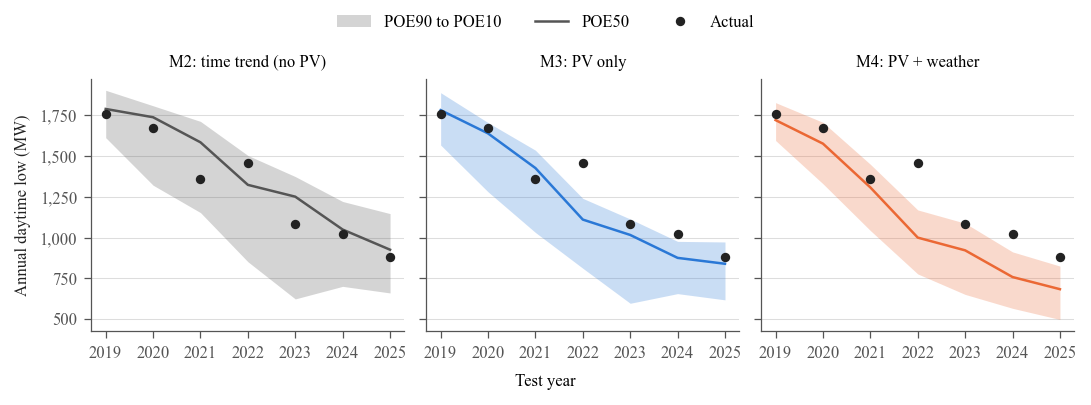

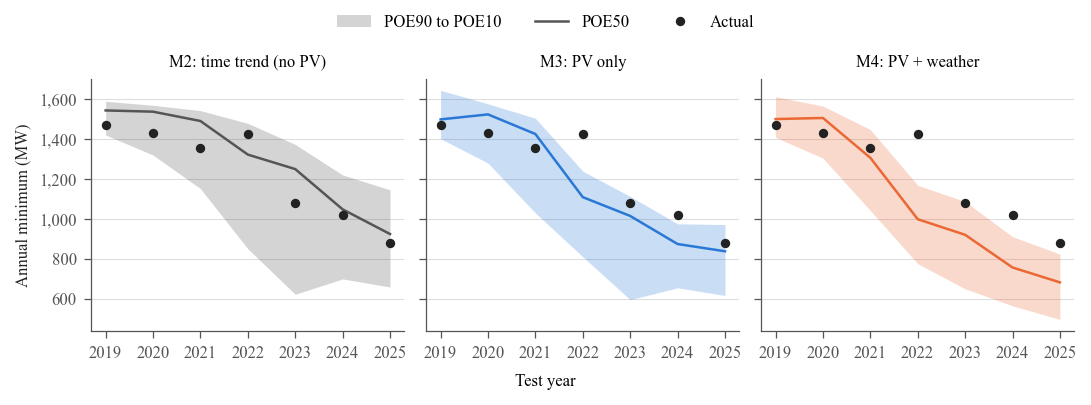

In [2]:
for target, ylabel in TARGETS.items():
    annual = forecasts[(forecasts["target"] == target) & (forecasts["level"] == "annual")]
    figure = plots.fig5_poe_bands(annual, ["M2", "M3", "M4"], ylabel)
    plots.save_figure(figure, archive, f"fig5_{target}")

## 3. Fig. 6 on the whole-day minimum

The monthly forecasts of the whole-day minimum scored separately for each calendar month, for M3, M4 and M5. Each point is the mean pinball loss over that month's valid test years.

The table is the figure's data; the saved CSV holds all six models.

month,1,2,3,4,5,6,7,8,9,10,11,12
model,,,,,,,,,,,,
M1,25,46,42,27,26,46,45,42,48,50,72,54
M2,44,54,35,31,29,40,32,36,35,38,37,37
M3,43,50,39,24,37,44,40,35,45,30,57,48
M4,42,46,40,26,41,45,45,46,57,27,64,47
M5,19,37,27,23,32,45,40,31,18,43,47,28
M6,27,28,44,26,41,62,57,52,34,76,40,24


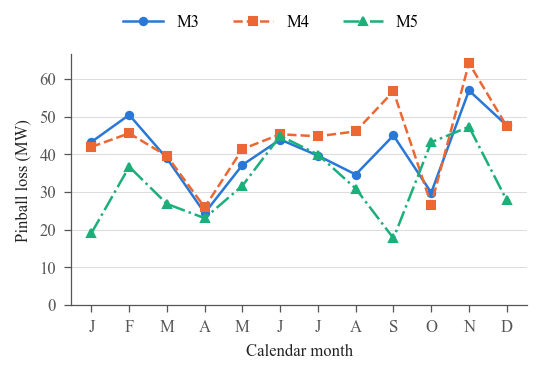

In [3]:
rows = forecasts[(forecasts["target"] == "minimum") & (forecasts["level"] == "monthly")]
by_month = evaluate.score(rows, ["model", "month"])
by_month.to_csv(archive / "fig6_minimum_data.csv")

figure = plots.fig6_monthly_pinball(by_month, ["M3", "M4", "M5"])
plots.save_figure(figure, archive, "fig6_minimum")
by_month["pinball_mean"].unstack("month").round()

## 4. Result

The files this notebook wrote to the archive.

In [4]:
written = ["fig5_daytime_low", "fig5_minimum", "fig6_minimum"]
for name in written:
    for suffix in (".png", ".pdf"):
        assert (archive / f"{name}{suffix}").exists()
print("Superseded figures in outputs/archive:", ", ".join(written))
print("Data behind the archived Fig. 6: fig6_minimum_data.csv")

Superseded figures in outputs/archive: fig5_daytime_low, fig5_minimum, fig6_minimum
Data behind the archived Fig. 6: fig6_minimum_data.csv
